In [ ]:
import pandas as pd
df = pd.read_csv('/content/H2.csv')
display(df.head())

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,7/3/2015
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,7/1/2015
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,4/30/2015
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,6/23/2015
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,4/2/2015


In [ ]:
print(df.shape)
print(df.columns)
print(df.info())

(79330, 31)
Index(['IsCanceled', 'LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth',
       'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth',
       'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children',
       'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel',
       'IsRepeatedGuest', 'PreviousCancellations',
       'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType',
       'BookingChanges', 'DepositType', 'Agent', 'Company',
       'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces',
       'TotalOfSpecialRequests', 'ReservationStatus', 'ReservationStatusDate'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64 

In [ ]:
# Count missing values in each column
print(df.isnull().sum())

IsCanceled                      0
LeadTime                        0
ArrivalDateYear                 0
ArrivalDateMonth                0
ArrivalDateWeekNumber           0
ArrivalDateDayOfMonth           0
StaysInWeekendNights            0
StaysInWeekNights               0
Adults                          0
Children                        4
Babies                          0
Meal                            0
Country                        24
MarketSegment                   0
DistributionChannel             0
IsRepeatedGuest                 0
PreviousCancellations           0
PreviousBookingsNotCanceled     0
ReservedRoomType                0
AssignedRoomType                0
BookingChanges                  0
DepositType                     0
Agent                           0
Company                         0
DaysInWaitingList               0
CustomerType                    0
ADR                             0
RequiredCarParkingSpaces        0
TotalOfSpecialRequests          0
ReservationSta

colummns that would cause leakage
direct leakge: reservation status and reservation status date

In [ ]:
df.drop(columns=['ReservationStatus'], inplace=True)
df.drop(columns=['ReservationStatusDate'], inplace=True)


In [ ]:
# Cell 2: Separate features and target, then split
from sklearn.model_selection import train_test_split

X = df.drop(columns=['IsCanceled'])
y = df['IsCanceled']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

checking for data imbalance

,Train Count,Train (%),Test Count,Test (%)
Not Canceled (0),36982,58.27,9246,58.28
Canceled (1),26482,41.73,6620,41.72


Imbalance Ratio (Majority : Minority): 1.40 : 1


/tmp/ipykernel_977/50184195.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


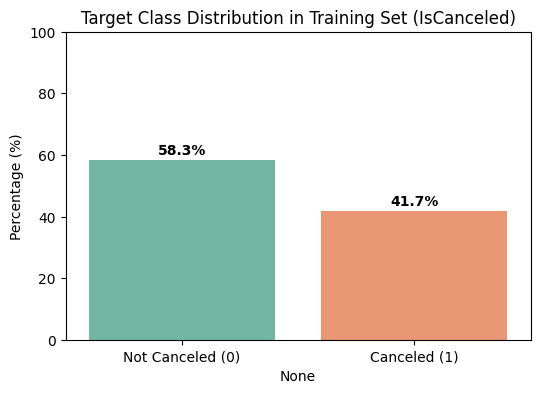

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Exact counts and percentages in training and testing sets
train_counts = y_train.value_counts()
train_props = y_train.value_counts(normalize=True) * 100

test_counts = y_test.value_counts()
test_props = y_test.value_counts(normalize=True) * 100

imbalance_df = pd.DataFrame({
    'Train Count': train_counts,
    'Train (%)': train_props.round(2),
    'Test Count': test_counts,
    'Test (%)': test_props.round(2),
})
imbalance_df.index = ['Not Canceled (0)', 'Canceled (1)']
display(imbalance_df)

# 2. Imbalance ratio (Majority / Minority)
imbalance_ratio = train_counts.max() / train_counts.min()
print(f'Imbalance Ratio (Majority : Minority): {imbalance_ratio:.2f} : 1')

# 3. Quick visualization
plt.figure(figsize=(6, 4))
sns.barplot(
    x=imbalance_df.index,
    y=imbalance_df['Train (%)'],
    palette='Set2',
)
plt.title('Target Class Distribution in Training Set (IsCanceled)')
plt.ylabel('Percentage (%)')
plt.ylim(0, 100)
for i, v in enumerate(imbalance_df['Train (%)']):
  plt.text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold')
plt.show()

Lead Time

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

train_eda = X_train.copy()
train_eda['IsCanceled'] = y_train

# 1. Summary stats split by cancellation status
display(train_eda.groupby('IsCanceled')['LeadTime'].describe())

,count,mean,std,min,25%,50%,75%,max
IsCanceled,,,,,,,,
0,36982.0,80.511979,89.656434,0.0,12.0,49.0,121.0,518.0
1,26482.0,150.578204,124.500623,0.0,50.0,115.0,228.0,629.0


date

In [ ]:
month_order = ['January','February','March','April','May','June','July',
               'August','September','October','November','December']
tmp = X_train.assign(y=y_train)
print(tmp.groupby("ArrivalDateMonth")["y"].agg(["mean", "count"]).reindex(month_order).round(3))

                   mean  count
ArrivalDateMonth              
January           0.390   3030
February          0.387   3946
March             0.368   5171
April             0.465   6005
May               0.442   6607
June              0.445   6340
July              0.412   6425
August            0.405   7245
September         0.421   5911
October           0.427   6051
November          0.383   3432
December          0.415   3301


In [ ]:
import pandas as pd

tmp = X_train.assign(y=y_train)
month_order = ['January','February','March','April','May','June','July',
               'August','September','October','November','December']

# 1. YEAR: does the cancellation rate drift between years?
print("By year:")
print(tmp.groupby("ArrivalDateYear")["y"].agg(["mean", "count"]).round(3))

# 2. WEEK NUMBER: is it redundant with month? (how many months does each week span?)
months_per_week = tmp.groupby("ArrivalDateWeekNumber")["ArrivalDateMonth"].nunique()
print("\nMonths spanned per week number:")
print(months_per_week.value_counts().sort_index())
print("Unique week numbers:", tmp["ArrivalDateWeekNumber"].nunique())

# 3. DAY OF MONTH: any pattern, or just noise around the base rate?
dom = tmp.groupby("ArrivalDateDayOfMonth")["y"].agg(["mean", "count"]).round(3)
print("\nDay of month: min / max rate:", dom["mean"].min(), "/", dom["mean"].max())
print("Overall base rate:", y_train.mean().round(3))
print(dom.T.to_string())

By year:
                  mean  count
ArrivalDateYear              
2015             0.437  10915
2016             0.406  30478
2017             0.423  22071

Months spanned per week number:
ArrivalDateMonth
1    36
2    17
Name: count, dtype: int64
Unique week numbers: 53

Day of month: min / max rate: 0.352 / 0.482
Overall base rate: 0.417
ArrivalDateDayOfMonth        1         2         3         4        5         6         7         8         9         10        11       12        13        14        15        16        17        18        19        20        21        22        23        24        25        26        27        28        29        30        31
mean                      0.458     0.394     0.441     0.401     0.43     0.369     0.439     0.482     0.429     0.369     0.352     0.42     0.402     0.451     0.452     0.445     0.464     0.386     0.412     0.419     0.401     0.412     0.369     0.402     0.382     0.416     0.412     0.434     0.392     0.476     0

In [ ]:
import pandas as pd

month_mapping = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12
}

for d in (X_train, X_test):
    # Build from the original text column so re-running the cell doesn't break anything
    d["month"] = d["ArrivalDateMonth"].map(month_mapping)

print("Unmapped months (train, test):", X_train["month"].isna().sum(), X_test["month"].isna().sum())

# Fixed categories 1..12, so train and test always get the same 12 columns
for name in ("X_train", "X_test"):
    d = globals()[name]
    d["month"] = pd.Categorical(d["month"], categories=range(1, 13))

X_train = pd.get_dummies(X_train, columns=["month"], prefix="month", dtype=int)
X_test = pd.get_dummies(X_test, columns=["month"], prefix="month", dtype=int)

# Drop the raw date columns (year, week number and day of month are excluded on purpose)
drop_cols = ["ArrivalDateYear", "ArrivalDateMonth", "ArrivalDateDayOfMonth", "ArrivalDateWeekNumber"]
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)

print([c for c in X_train.columns if c.startswith("month_")])

Unmapped months (train, test): 0 0
['month_1', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12']


Totalnights=Staysinweekends+weekdays and binary flag for zero nights

In [ ]:
X_train['TotalNights'] = (
    X_train['StaysInWeekendNights'] +
    X_train['StaysInWeekNights']
)

X_test['TotalNights'] = (
    X_test['StaysInWeekendNights'] +
    X_test['StaysInWeekNights']
)

X_train['WeekendOrNo'] = (
    X_train['StaysInWeekendNights'] > 0
).astype(int)

X_test['WeekendOrNo'] = (
    X_test['StaysInWeekendNights'] > 0
).astype(int)

In [ ]:
zero_nights_train = (X_train["TotalNights"] == 0).sum()
zero_nights_test = (X_test["TotalNights"] == 0).sum()

print(f"Number of bookings with 0 total nights in training set: {zero_nights_train}")
print(f"Number of bookings with 0 total nights in testing set: {zero_nights_test}")

Number of bookings with 0 total nights in training set: 263
Number of bookings with 0 total nights in testing set: 68


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Combine X_train and y_train safely without touching X_test
train_eda = X_train.copy()
train_eda['IsCanceled'] = y_train

# 1. Create a flag comparing TotalNights == 0 vs TotalNights > 0
train_eda['StayType'] = train_eda['TotalNights'].apply(
    lambda x: 'Zero Nights (TotalNights == 0)' if x == 0 else '1+ Nights'
)

# 2. Summary table: exact counts, cancellations, and cancellation rate
summary = (
    train_eda.groupby('StayType')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .reset_index()
)
display(summary)

,StayType,total_bookings,canceled_count,cancellation_rate
0,1+ Nights,63201,26465,0.418743
1,Zero Nights (TotalNights == 0),263,17,0.064639


In [ ]:
X_train['IsZeroNights'] = (X_train['TotalNights'] == 0).astype(int)
X_test['IsZeroNights'] = (X_test['TotalNights'] == 0).astype(int)

In [ ]:
tmp = X_train.assign(y=y_train)
print(tmp.groupby("WeekendOrNo")["y"].agg(["mean", "count"]).round(3))
print(tmp.groupby(tmp["TotalNights"].clip(upper=8))["y"].agg(["mean", "count"]).round(3))

              mean  count
WeekendOrNo              
0            0.430  30273
1            0.407  33055
              mean  count
TotalNights              
0            0.043    207
1            0.306  10590
2            0.487  17203
3            0.445  17068
4            0.384  10025
5            0.360   3991
6            0.454   1625
7            0.395   1643
8            0.569    976


In [ ]:
X_train = X_train.drop(columns="WeekendOrNo")
X_test = X_test.drop(columns="WeekendOrNo")

In [ ]:
X_train.drop(
    columns=['StaysInWeekendNights', 'StaysInWeekNights'],
    inplace=True
)
X_test.drop(
    columns=['StaysInWeekendNights', 'StaysInWeekNights'],
    inplace=True
)

guests

In [ ]:
# 1. Inspect zero-adult bookings in train and test
print('Bookings with zero adults in df:', (df['Adults'] == 0).sum())
print(
    'Training bookings with zero adults:', (X_train['Adults'] == 0).sum()
)
print('Their IsCanceled distribution in training:')
print(y_train[X_train['Adults'] == 0].value_counts(dropna=False))

print(
    '\nTesting bookings with zero adults:', (X_test['Adults'] == 0).sum()
)
print('Their IsCanceled distribution in testing:')
print(y_test[X_test['Adults'] == 0].value_counts(dropna=False))

Bookings with zero adults in df: 390
Training bookings with zero adults: 326
Their IsCanceled distribution in training:
IsCanceled
0    238
1     88
Name: count, dtype: int64

Testing bookings with zero adults: 64
Their IsCanceled distribution in testing:
IsCanceled
0    45
1    19
Name: count, dtype: int64


In [ ]:
# 2. Combine train and test zero-adult rows to inspect IsCanceled
zero_adults = pd.concat([
    X_train[X_train['Adults'] == 0].assign(
        IsCanceled=y_train[X_train['Adults'] == 0]
    ),
    X_test[X_test['Adults'] == 0].assign(
        IsCanceled=y_test[X_test['Adults'] == 0]
    ),
])

print(
    zero_adults[['Adults', 'Children', 'Babies', 'IsCanceled']]
    .sort_values(['IsCanceled'])
    .to_string()
)

print(
    'Zero adults, children, and babies:',
    (
        (zero_adults['Adults'] == 0)
        & (zero_adults['Children'] == 0)
        & (zero_adults['Babies'] == 0)
    ).sum(),
)



       Adults  Children  Babies  IsCanceled
74848       0       0.0       0           0
70967       0       0.0       0           0
55608       0       2.0       0           0
64171       0       0.0       0           0
42227       0       2.0       0           0
67097       0       0.0       0           0
43145       0       2.0       0           0
69885       0       0.0       0           0
6160        0       2.0       0           0
64679       0       2.0       0           0
8840        0       1.0       0           0
74851       0       0.0       0           0
6486        0       2.0       0           0
7115        0       2.0       0           0
62551       0       0.0       0           0
76191       0       0.0       0           0
8955        0       2.0       0           0
63204       0       0.0       0           0
55066       0       2.0       0           0
960         0       0.0       0           0
67483       0       0.0       0           0
50870       0       0.0       0 

In [ ]:
no_guests = (zero_adults['Children'] == 0) & (zero_adults['Babies'] == 0)
print('\nCancellation rate by group within zero-adult bookings:')
print(
    'No guests cancellation rate:', zero_adults.loc[no_guests, 'IsCanceled'].mean()
)
print(
    'Guests present cancellation rate:',
    zero_adults.loc[~no_guests, 'IsCanceled'].mean(),
)


Cancellation rate by group within zero-adult bookings:
No guests cancellation rate: 0.1377245508982036
Guests present cancellation rate: 0.37668161434977576


In [ ]:
# 1. Fill any missing Children values with 0 before summing
X_train['Children'] = X_train['Children'].fillna(0)
X_test['Children'] = X_test['Children'].fillna(0)

# 2. Compute total_guests
X_train['total_guests'] = (
    X_train['Adults'] + X_train['Children'] + X_train['Babies']
)
X_test['total_guests'] = (
    X_test['Adults'] + X_test['Children'] + X_test['Babies']
)

# 3. Filter out rows where Adults == 0 OR total_guests == 0
# (Hotels require at least 1 adult per room)
train_mask = (X_train['Adults'] > 0) & (X_train['total_guests'] > 0)
test_mask = (X_test['Adults'] > 0) & (X_test['total_guests'] > 0)

X_train = X_train.loc[train_mask].copy()
y_train = y_train.loc[train_mask].copy()

X_test = X_test.loc[test_mask].copy()
y_test = y_test.loc[test_mask].copy()

# 4. Verify results
print('Invalid adult/guest rows in training:', (~train_mask).sum())
print('Invalid adult/guest rows in testing:', (~test_mask).sum())
print('Remaining training rows:', len(X_train))
print('Remaining testing rows:', len(X_test))

Invalid adult/guest rows in training: 191
Invalid adult/guest rows in testing: 32
Remaining training rows: 63137
Remaining testing rows: 15801


In [ ]:
guest_columns_to_drop = ['Adults', 'Children', 'Babies']

X_train.drop(columns=guest_columns_to_drop, inplace=True, errors='ignore')
X_test.drop(columns=guest_columns_to_drop, inplace=True, errors='ignore')

print("Remaining columns in X_train:", X_train.columns.tolist())

Remaining columns in X_train: ['LeadTime', 'Country', 'IsRepeatedGuest', 'ReservedRoomType', 'BookingChanges', 'ADR', 'TotalOfSpecialRequests', 'TotalNights', 'IsZeroNights', 'total_guests', 'Meal_BB       ', 'Meal_FB       ', 'Meal_HB       ', 'Meal_SC       ', 'MarketSegment_Aviation', 'MarketSegment_Complementary', 'MarketSegment_Corporate', 'MarketSegment_Direct', 'MarketSegment_Groups', 'MarketSegment_Offline TA/TO', 'MarketSegment_Online TA', 'has_prev_cancellation', 'has_prev_booking_ok', 'Agent_te', 'has_company', 'CustomerType_Transient_Party', 'CustomerType_Contract', 'CustomerType_Group', 'is_free_stay', 'needs_parking', 'month_1', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12']


Meal

,total_bookings,canceled_count,cancellation_rate
Meal,,,
BB,49700,21314,0.428853
SC,8399,3149,0.374926
HB,5195,1973,0.379788
FB,35,27,0.771429


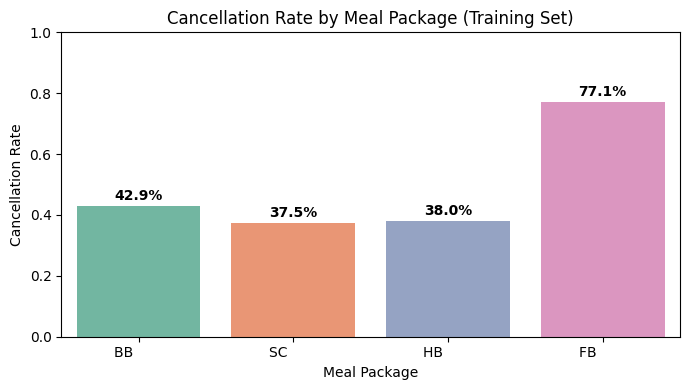

In [ ]:
# 1. Exact counts and cancellation rates per Meal package (on training set)
meal_summary = (
    pd.DataFrame({'Meal': X_train['Meal'], 'IsCanceled': y_train})
    .groupby('Meal')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)
display(meal_summary)

# 2. Proper visualization: Cancellation rate barplot
plt.figure(figsize=(7, 4))
sns.barplot(
    x=meal_summary.index,
    y=meal_summary['cancellation_rate'],
    hue=meal_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by Meal Package (Training Set)')
plt.xlabel('Meal Package')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(meal_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import OneHotEncoder

if 'Meal' in X_train.columns:
  encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

  meal_train_array = encoder.fit_transform(X_train[['Meal']])
  meal_test_array = encoder.transform(X_test[['Meal']])

  encoded_feature_names = encoder.get_feature_names_out(['Meal'])

  meal_train_encoded = pd.DataFrame(
      meal_train_array, columns=encoded_feature_names, index=X_train.index
  )
  meal_test_encoded = pd.DataFrame(
      meal_test_array, columns=encoded_feature_names, index=X_test.index
  )

  X_train = pd.concat(
      [X_train.drop(columns=['Meal']), meal_train_encoded], axis=1
  )
  X_test = pd.concat([X_test.drop(columns=['Meal']), meal_test_encoded], axis=1)

print('Encoded Meal columns:', [c for c in X_train.columns if 'Meal_' in c])

Encoded Meal columns: ['Meal_BB       ', 'Meal_FB       ', 'Meal_HB       ', 'Meal_SC       ']


In [ ]:
# Check all remaining columns, data types, and any remaining missing values
summary_df = pd.DataFrame({
    'dtype': X_train.dtypes,
    'train_nulls': X_train.isna().sum(),
    'test_nulls': X_test.isna().sum(),
    'unique_train': X_train.nunique(),
})

print(f'Total columns: {X_train.shape[1]}')
display(summary_df)

# Specifically list any remaining object/categorical columns
remaining_cat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print('\nRemaining categorical columns:', remaining_cat)

Total columns: 33


,dtype,train_nulls,test_nulls,unique_train
LeadTime,int64,0,0,449
ArrivalDateYear,int64,0,0,3
ArrivalDateMonth,object,0,0,12
ArrivalDateWeekNumber,int64,0,0,53
ArrivalDateDayOfMonth,int64,0,0,31
Adults,int64,0,0,5
Children,float64,0,0,4
Babies,int64,0,0,5
Country,object,10,6,160
MarketSegment,object,0,0,8



Remaining categorical columns: ['ArrivalDateMonth', 'Country', 'MarketSegment', 'DistributionChannel', 'ReservedRoomType', 'AssignedRoomType', 'DepositType', 'Agent', 'Company', 'CustomerType']


country - has nulls

In [ ]:
# All unique values (including missing), with counts
counts = X_train["Country"].value_counts(dropna=False)
print("Unique values:", X_train["Country"].nunique(dropna=False))
print(counts.to_string())          # to_string() prints every row, no "..." truncation

# Just the sorted list of codes
print(sorted(X_train["Country"].dropna().unique()))

Unique values: 161
Country
PRT    24661
FRA     7011
DEU     4901
GBR     4226
ESP     3710
ITA     2678
BEL     1485
BRA     1439
USA     1306
NLD     1242
CHE     1058
IRL      967
AUT      844
CHN      692
SWE      551
ISR      524
POL      474
CN       445
NOR      403
RUS      357
DNK      294
AGO      273
AUS      262
ROU      257
FIN      236
TUR      182
LUX      169
JPN      153
HUN      148
MAR      142
ARG      125
CZE      109
KOR      103
GRC       93
IND       93
DZA       80
SRB       76
HRV       73
IRN       70
MEX       65
BGR       54
COL       46
MOZ       46
NZL       45
ZAF       42
SVK       40
ISL       40
EST       39
UKR       38
THA       38
SVN       36
SAU       36
CHL       36
CYP       35
TUN       32
TWN       31
LTU       30
ARE       29
SGP       29
IDN       26
EGY       24
NGA       23
PER       20
VEN       20
LBN       19
URY       19
ECU       18
LVA       18
HKG       17
PHL       16
MAC       15
CPV       15
KAZ       14
BLR       14
IRQ       1

Total unique countries in X_train: 161


,total_bookings,canceled_count,cancellation_rate
Country,,,
PRT,24661,16011,0.649244
FRA,7011,1387,0.197832
DEU,4901,855,0.174454
GBR,4226,1255,0.296971
ESP,3710,1067,0.287601
ITA,2678,1027,0.383495
BEL,1485,323,0.217508
BRA,1439,581,0.403753
USA,1306,360,0.275651


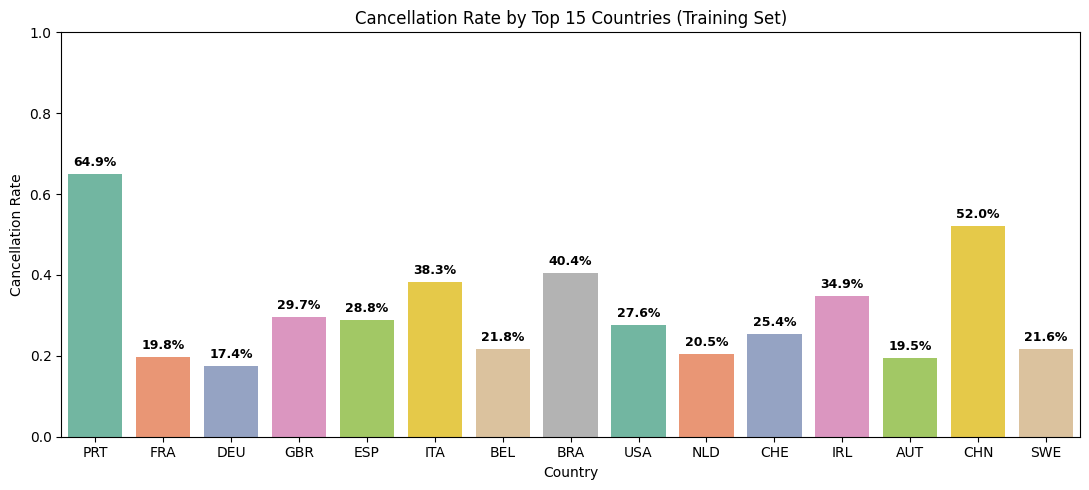

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Exact counts and cancellation rates per Country (on training set)
country_summary = (
    pd.DataFrame({
        'Country': X_train['Country'].fillna('Missing'),
        'IsCanceled': y_train,
    })
    .groupby('Country')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

print(f'Total unique countries in X_train: {len(country_summary)}')
display(country_summary.head(20))

# 2. Barplot of Top 15 countries by booking volume
top_n = 15
top_countries = country_summary.head(top_n)

plt.figure(figsize=(11, 5))
sns.barplot(
    x=top_countries.index,
    y=top_countries['cancellation_rate'],
    hue=top_countries.index,
    palette='Set2',
    legend=False,
)
plt.title(f'Cancellation Rate by Top {top_n} Countries (Training Set)')
plt.xlabel('Country')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(top_countries['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
print("CN rows in train:", (X_train["Country"] == "CN").sum())
print("CN rows in test: ", (X_test["Country"] == "CN").sum())

for d in (X_train, X_test):
    d["Country"] = d["Country"].replace({"CN": "CHN"})

CN rows in train: 445
CN rows in test:  124


In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
# 1. Fill missing country codes
X_train["Country"] = X_train["Country"].fillna("Missing")
X_test["Country"] = X_test["Country"].fillna("Missing")

# 2. Fit the encoder on TRAIN only
country_encoder = OneHotEncoder(
    min_frequency=500,                      # lower to ~200 if CHN/BRA get lumped in
    handle_unknown="infrequent_if_exist",   # unseen test countries go to the infrequent bucket
    sparse_output=False,
)
country_train_arr = country_encoder.fit_transform(X_train[["Country"]])
country_test_arr = country_encoder.transform(X_test[["Country"]])

# 3. Inspect what got its own column and what was grouped
print("Own columns:", [c for c in country_encoder.categories_[0]
                       if c not in country_encoder.infrequent_categories_[0]])
print("Grouped as infrequent:", list(country_encoder.infrequent_categories_[0]))

# 4. Build DataFrames with the original index so the concat lines up
country_cols = country_encoder.get_feature_names_out(["Country"])
country_train_df = pd.DataFrame(country_train_arr, columns=country_cols, index=X_train.index)
country_test_df = pd.DataFrame(country_test_arr, columns=country_cols, index=X_test.index)

Own columns: ['AUT', 'BEL', 'BRA', 'CHE', 'CHN', 'DEU', 'ESP', 'FRA', 'GBR', 'IRL', 'ISR', 'ITA', 'NLD', 'PRT', 'SWE', 'USA']
Grouped as infrequent: ['ABW', 'AGO', 'AIA', 'ALB', 'AND', 'ARE', 'ARG', 'ARM', 'ASM', 'ATA', 'ATF', 'AUS', 'AZE', 'BEN', 'BFA', 'BGD', 'BGR', 'BHR', 'BIH', 'BLR', 'BOL', 'BRB', 'CAF', 'CHL', 'CIV', 'CMR', 'COL', 'COM', 'CPV', 'CRI', 'CUB', 'CYP', 'CZE', 'DMA', 'DNK', 'DOM', 'DZA', 'ECU', 'EGY', 'EST', 'ETH', 'FIN', 'FRO', 'GAB', 'GEO', 'GGY', 'GHA', 'GIB', 'GLP', 'GNB', 'GRC', 'GTM', 'GUY', 'HKG', 'HND', 'HRV', 'HUN', 'IDN', 'IMN', 'IND', 'IRN', 'IRQ', 'ISL', 'JAM', 'JEY', 'JOR', 'JPN', 'KAZ', 'KEN', 'KHM', 'KIR', 'KNA', 'KOR', 'KWT', 'LAO', 'LBN', 'LBY', 'LCA', 'LIE', 'LKA', 'LTU', 'LUX', 'LVA', 'MAC', 'MAR', 'MCO', 'MDV', 'MEX', 'MKD', 'MLI', 'MLT', 'MMR', 'MNE', 'MOZ', 'MRT', 'MUS', 'MYS', 'MYT', 'Missing', 'NAM', 'NCL', 'NGA', 'NIC', 'NOR', 'NZL', 'OMN', 'PAK', 'PAN', 'PER', 'PHL', 'POL', 'PRI', 'PRY', 'QAT', 'ROU', 'RUS', 'SAU', 'SEN', 'SGP', 'SLE', 'SLV',

MarketSegment

In [ ]:
segments_counts = df["MarketSegment"].value_counts()

print("segments counts:")
print(segments_counts)

segments counts:
MarketSegment
Online TA        38748
Offline TA/TO    16747
Groups           13975
Direct            6093
Corporate         2986
Complementary      542
Aviation           237
Undefined            2
Name: count, dtype: int64


In [ ]:
# Training set for Undefined MarketSegment
undefined_train = X_train['MarketSegment'] == 'Undefined'

print("Training set — Undefined MarketSegment:")
print(y_train.loc[undefined_train].describe())
print("Number of rows:", undefined_train.sum())

# Test set for Undefined MarketSegment
undefined_test = X_test['MarketSegment'] == 'Undefined'

print("\nTest set — Undefined MarketSegment:")
print(y_test.loc[undefined_test].describe())
print("Number of rows:", undefined_test.sum())

Training set — Undefined MarketSegment:
count    1.0
mean     1.0
std      NaN
min      1.0
25%      1.0
50%      1.0
75%      1.0
max      1.0
Name: IsCanceled, dtype: float64
Number of rows: 1

Test set — Undefined MarketSegment:
count    1.0
mean     1.0
std      NaN
min      1.0
25%      1.0
50%      1.0
75%      1.0
max      1.0
Name: IsCanceled, dtype: float64
Number of rows: 1


In [ ]:
#drop undefined rows - both iscanceled = 1
train_mask = X_train['MarketSegment'] != 'Undefined'
test_mask = X_test['MarketSegment'] != 'Undefined'

X_train = X_train.loc[train_mask].copy()
y_train = y_train.loc[train_mask].copy()

X_test = X_test.loc[test_mask].copy()
y_test = y_test.loc[test_mask].copy()

# Verify removal
print('Undefined in train:', (X_train['MarketSegment'] == 'Undefined').sum())
print('Undefined in test:', (X_test['MarketSegment'] == 'Undefined').sum())
print('Remaining train rows:', len(X_train), '| Remaining test rows:', len(X_test))

Undefined in train: 0
Undefined in test: 0
Remaining train rows: 63328 | Remaining test rows: 15833


,total_bookings,canceled_count,cancellation_rate
MarketSegment,,,
Online TA,30991,11654,0.376045
Offline TA/TO,13350,5707,0.427491
Groups,11135,7676,0.689358
Direct,4841,831,0.171659
Corporate,2384,503,0.210990
Complementary,441,47,0.106576
Aviation,186,44,0.236559


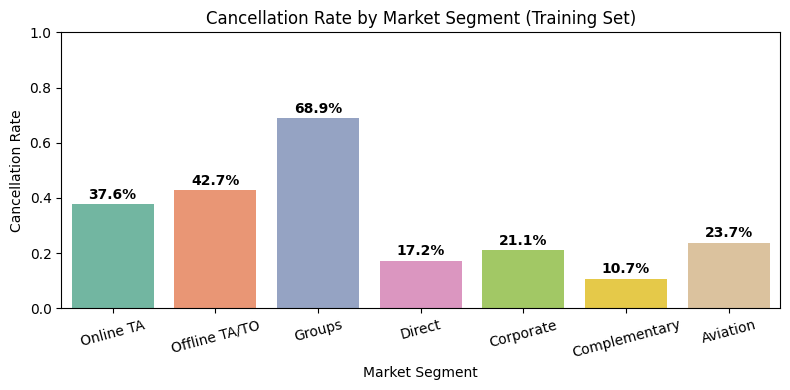

In [ ]:
# 1. Exact counts and cancellation rates per MarketSegment (on training set only)
market_summary = (
    pd.DataFrame(
        {'MarketSegment': X_train['MarketSegment'], 'IsCanceled': y_train}
    )
    .groupby('MarketSegment')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by MarketSegment
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by Market Segment (Training Set)')
plt.xlabel('Market Segment')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# 1. Clean whitespace
X_train["MarketSegment"] = X_train["MarketSegment"].str.strip()
X_test["MarketSegment"] = X_test["MarketSegment"].str.strip()

# 2. Fit the encoder on TRAIN only
seg_encoder = OneHotEncoder(
    handle_unknown="ignore",    # a level unseen in train becomes all zeros in test
    sparse_output=False,
)
seg_train_arr = seg_encoder.fit_transform(X_train[["MarketSegment"]])
seg_test_arr = seg_encoder.transform(X_test[["MarketSegment"]])

# 3. Build DataFrames with the original index so the concat lines up
seg_cols = seg_encoder.get_feature_names_out(["MarketSegment"])
seg_train_df = pd.DataFrame(seg_train_arr, columns=seg_cols, index=X_train.index)
seg_test_df = pd.DataFrame(seg_test_arr, columns=seg_cols, index=X_test.index)

# 4. Replace the raw column with the encoded ones
X_train = pd.concat([X_train.drop(columns="MarketSegment"), seg_train_df], axis=1)
X_test = pd.concat([X_test.drop(columns="MarketSegment"), seg_test_df], axis=1)

print("Encoded MarketSegment columns:", list(seg_cols))
print("Total features:", X_train.shape[1])

Encoded MarketSegment columns: ['MarketSegment_Aviation', 'MarketSegment_Complementary', 'MarketSegment_Corporate', 'MarketSegment_Direct', 'MarketSegment_Groups', 'MarketSegment_Offline TA/TO', 'MarketSegment_Online TA']
Total features: 39


In [ ]:
# Check all current column names, data types, and remaining nulls/categoricals
print(f"Total columns: {X_train.shape[1]}")
print("Column names:", list(X_train.columns))

# Quick overview of any remaining object/categorical columns or missing values
remaining_cat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
remaining_nulls = X_train.columns[X_train.isna().any() | X_test.isna().any()].tolist()

print("\nRemaining categorical columns:", remaining_cat)
print("Columns with missing values (train or test):", remaining_nulls)

Total columns: 39
Column names: ['LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'Adults', 'Children', 'Babies', 'Country', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType', 'BookingChanges', 'DepositType', 'Agent', 'Company', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'TotalNights', 'WeekendOrNo', 'IsZeroNights', 'total_guests', 'Meal_BB       ', 'Meal_FB       ', 'Meal_HB       ', 'Meal_SC       ', 'MarketSegment_Aviation', 'MarketSegment_Complementary', 'MarketSegment_Corporate', 'MarketSegment_Direct', 'MarketSegment_Groups', 'MarketSegment_Offline TA/TO', 'MarketSegment_Online TA']

Remaining categorical columns: ['ArrivalDateMonth', 'Country', 'DistributionChannel', 'ReservedRoomType', 'AssignedRoomType', 'DepositType', 'Agent', 'Company', 'CustomerType']
Columns with missing values (tra

DistributionChannel - dropped


In [ ]:
channel_counts = df["DistributionChannel"].value_counts()

print("DistributionChannel:")
print(channel_counts)

DistributionChannel:
DistributionChannel
TA/TO        68945
Direct        6780
Corporate     3408
GDS            193
Undefined        4
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
DistributionChannel,,,
TA/TO,55082,24839,0.450946
Direct,5385,963,0.178830
Corporate,2709,629,0.232189
GDS,150,29,0.193333
Undefined,2,2,1.000000


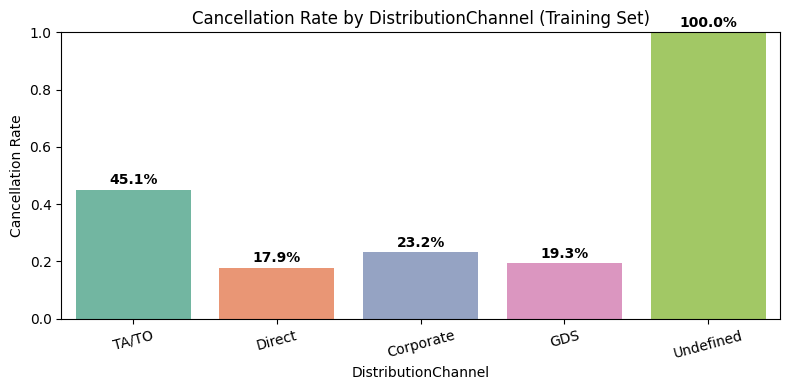

In [ ]:
# 1. Exact counts and cancellation rates per distribution (on training set only)
market_summary = (
    pd.DataFrame(
        {'DistributionChannel': X_train['DistributionChannel'], 'IsCanceled': y_train}
    )
    .groupby('DistributionChannel')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by DistributionChannel
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by DistributionChannel (Training Set)')
plt.xlabel('DistributionChannel')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
pd.crosstab(
    df["MarketSegment"],
    df["DistributionChannel"]
)

DistributionChannel,Corporate,Direct,GDS,TA/TO,Undefined
MarketSegment,,,,,
Aviation,227,0,0,10,0
Complementary,69,437,0,36,0
Corporate,2636,56,0,294,0
Direct,6,6048,1,37,1
Groups,240,177,0,13558,0
Offline TA/TO,198,6,45,16498,0
Online TA,32,56,147,38512,1
Undefined,0,0,0,0,2


small test to see its gain

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mutual_info_score
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import OneHotEncoder

# Note: If you already encoded MarketSegment into MarketSegment_* columns in X_train,
# reconstruct the original label just for this diagnostic check:
if 'MarketSegment' in X_train.columns:
  ms_series = X_train['MarketSegment']
else:
  ms_cols = [c for c in X_train.columns if c.startswith('MarketSegment_')]
  ms_series = (
      X_train[ms_cols].idxmax(axis=1).str.replace('MarketSegment_', '', n=1)
  )

dc_series = X_train['DistributionChannel'].str.strip()

diag_df = pd.DataFrame(
    {'MarketSegment': ms_series, 'DistributionChannel': dc_series, 'IsCanceled': y_train}
)

# 1. Cancellation rate & count for every (MarketSegment, DistributionChannel) pair
breakdown = (
    diag_df.groupby(['MarketSegment', 'DistributionChannel'])['IsCanceled']
    .agg(bookings='count', cancel_rate='mean')
    .sort_values(['MarketSegment', 'bookings'], ascending=[True, False])
)
print('=== Cancellation Rate by MarketSegment x DistributionChannel ===')
display(breakdown)

# 2. Mutual Information with IsCanceled (higher = more predictive signal)
mi_ms = mutual_info_score(diag_df['MarketSegment'], diag_df['IsCanceled'])
mi_dc = mutual_info_score(diag_df['DistributionChannel'], diag_df['IsCanceled'])
print(f'\nMutual Information with IsCanceled:')
print(f'  MarketSegment alone:       {mi_ms:.5f}')
print(f'  DistributionChannel alone: {mi_dc:.5f}')

# 3. Does adding DistributionChannel to MarketSegment improve 5-fold CV ROC-AUC?
ohe = OneHotEncoder(handle_unknown='ignore')
X_ms_only = ohe.fit_transform(diag_df[['MarketSegment']])
X_both = ohe.fit_transform(diag_df[['MarketSegment', 'DistributionChannel']])

clf = LogisticRegression(max_iter=1000)
auc_ms = cross_val_score(
    clf, X_ms_only, diag_df['IsCanceled'], cv=5, scoring='roc_auc'
).mean()
auc_both = cross_val_score(
    clf, X_both, diag_df['IsCanceled'], cv=5, scoring='roc_auc'
).mean()

print(f'\n5-Fold CV ROC-AUC:')
print(f'  MarketSegment only:                  {auc_ms:.5f}')
print(f'  MarketSegment + DistributionChannel: {auc_both:.5f}')
print(f'  Net gain from DistributionChannel:   {auc_both - auc_ms:+.5f}')

=== Cancellation Rate by MarketSegment x DistributionChannel ===


bookings  cancel_rate
MarketSegment DistributionChannel                       
Aviation      Corporate                 176     0.244318
              TA/TO                      10     0.100000
Complementary Direct                    357     0.100840
              Corporate                  55     0.181818
              TA/TO                      29     0.034483
Corporate     Corporate                2103     0.203994
              TA/TO                     238     0.306723
              Direct                     43     0.023256
Direct        Direct                   4803     0.171976
              TA/TO                      32     0.031250
              Corporate                   4     0.750000
              GDS                         1     0.000000
              Undefined                   1     1.000000
Groups        TA/TO                   10819     0.696552
              Corporate                 181     0.243094
              Direct                    135     0.711111
Offline TA/TO TA/TO                   13147     0.426942
              Corporate                 164     0.536585
              GDS                        34     0.147059
              Direct                      5     0.200000
Online TA     TA/TO                   30807     0.376992
              GDS                       115     0.208696
              Direct                     42     0.071429
              Corporate                  26     0.461538
              Undefined                   1     1.000000


Mutual Information with IsCanceled:
  MarketSegment alone:       0.04432
  DistributionChannel alone: 0.01661

5-Fold CV ROC-AUC:
  MarketSegment only:                  0.64692
  MarketSegment + DistributionChannel: 0.64720
  Net gain from DistributionChannel:   +0.00028


In [ ]:
X_train.drop(columns=['DistributionChannel'], errors='ignore', inplace=True)
X_test.drop(columns=['DistributionChannel'], errors='ignore', inplace=True)

print("Remaining categorical columns:", X_train.select_dtypes(include=['object', 'category']).columns.tolist())
print("Columns with missing values:", X_train.columns[X_train.isna().any() | X_test.isna().any()].tolist())

Remaining categorical columns: ['ArrivalDateMonth', 'Country', 'ReservedRoomType', 'AssignedRoomType', 'DepositType', 'Agent', 'Company', 'CustomerType']
Columns with missing values: []


**guest history**

IsRepeatedGuest

In [ ]:
print(df["IsRepeatedGuest"].value_counts())

IsRepeatedGuest
0    77298
1     2032
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
IsRepeatedGuest,,,
0,61721,26103,0.422919
1,1607,359,0.223398


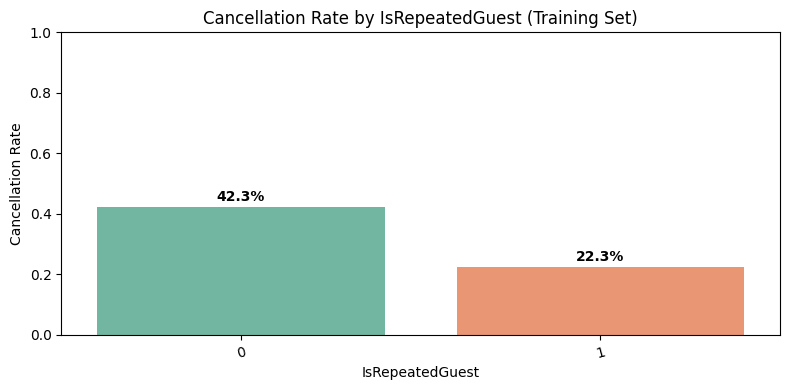

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'IsRepeatedGuest': X_train['IsRepeatedGuest'], 'IsCanceled': y_train}
    )
    .groupby('IsRepeatedGuest')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by IsRepeatedGuest (Training Set)')
plt.xlabel('IsRepeatedGuest')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
for name, df_split in [("Train", X_train), ("Test", X_test)]:
    col = df_split["IsRepeatedGuest"]
    print(f"=== {name} ===")
    print("Dtype:", col.dtype)
    print("Missing values:", col.isna().sum())
    print("Unique values:", sorted(col.unique().tolist()))

=== Train ===
Dtype: int64
Missing values: 0
Unique values: [0, 1]
=== Test ===
Dtype: int64
Missing values: 0
Unique values: [0, 1]


PreviousCancellations

In [ ]:
print(df["PreviousCancellations"].value_counts())

PreviousCancellations
0     73941
1      5155
2        72
3        51
11       35
4        25
6        22
5        16
13       12
21        1
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
PreviousCancellations,,,
0,59026,22466,0.380612
1,4110,3951,0.961314
2,57,11,0.192982
3,44,3,0.068182
11,28,7,0.250000
4,19,4,0.210526
6,18,7,0.388889
5,13,1,0.076923
13,12,11,0.916667


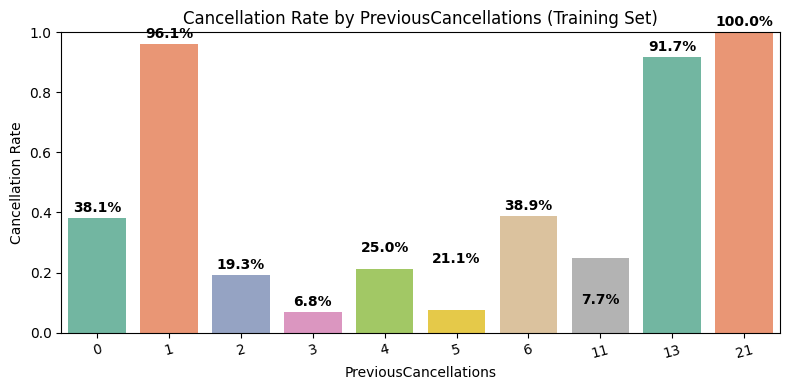

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'PreviousCancellations': X_train['PreviousCancellations'], 'IsCanceled': y_train}
    )
    .groupby('PreviousCancellations')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by PreviousCancellations (Training Set)')
plt.xlabel('PreviousCancellations')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
print(pd.crosstab(X_train["PreviousCancellations"], X_train["IsRepeatedGuest"], normalize="index").round(3))

IsRepeatedGuest            0      1
PreviousCancellations              
0                      0.983  0.017
1                      0.895  0.105
2                      0.035  0.965
3                      0.023  0.977
4                      0.000  1.000
5                      0.000  1.000
6                      0.333  0.667
11                     0.214  0.786
13                     0.000  1.000
21                     0.000  1.000


In [ ]:
tmp = X_train.assign(y=y_train)
print(tmp.groupby(["ArrivalDateYear", "PreviousCancellations"])["y"].agg(["mean", "count"]).round(3))

                                        mean  count
ArrivalDateYear PreviousCancellations              
2015            0                      0.232   7955
                1                      0.997   2928
                2                      0.200     10
                11                     1.000      1
                21                     1.000      1
2016            0                      0.388  29207
                1                      0.949   1073
                2                      0.226     31
                3                      0.073     41
                4                      0.000      8
                5                      0.111      9
                6                      1.000      7
                11                     0.222     27
                13                     0.917     12
2017            0                      0.425  21864
                1                      0.138    109
                2                      0.125     16
            

In [ ]:
# Rows where the guest is NOT a repeat guest but has previous cancellations
mask = (X_train["IsRepeatedGuest"] == 0) & (X_train["PreviousCancellations"] > 0)
suspicious = X_train[mask]

print("Rows:", mask.sum(), "out of", len(X_train), f"({mask.mean():.2%})")
print("\nBy PreviousCancellations:")
print(suspicious["PreviousCancellations"].value_counts().sort_index())

# Cancellation rate in this group vs. everyone else
print("\nCancellation rate, suspicious group:", y_train[mask].mean().round(3))
print("Cancellation rate, all other rows:   ", y_train[~mask].mean().round(3))

# Which years do these rows come from?
print("\nBy arrival year:")
print(suspicious["ArrivalDateYear"].value_counts().sort_index())

# Look at a sample of the rows
cols = ["IsRepeatedGuest", "PreviousCancellations", "PreviousBookingsNotCanceled",
        "ArrivalDateYear", "MarketSegment", "DepositType"]
print(suspicious[[c for c in cols if c in suspicious.columns]].head(20))

Rows: 3692 out of 63328 (5.83%)

By PreviousCancellations:
PreviousCancellations
1     3677
2        2
3        1
6        6
11       6
Name: count, dtype: int64

Cancellation rate, suspicious group: 1.0
Cancellation rate, all other rows:    0.382

By arrival year:
ArrivalDateYear
2015    2681
2016    1011
Name: count, dtype: int64
       IsRepeatedGuest  PreviousCancellations  PreviousBookingsNotCanceled  \
35282                0                      1                            0   
40371                0                      1                            0   
42285                0                      1                            0   
35924                0                      1                            0   
33849                0                      1                            0   
41872                0                      1                            0   
36861                0                      1                            0   
35056                0                    

In [ ]:
X_train['has_prev_cancellation'] = (X_train['PreviousCancellations'] > 0).astype(int)
X_test['has_prev_cancellation'] = (X_test['PreviousCancellations'] > 0).astype(int)


In [ ]:
X_train.drop(columns=['PreviousCancellations'], inplace=True)
X_test.drop(columns=['PreviousCancellations'], inplace=True)

print("Train distribution:\n", X_train['has_prev_cancellation'].value_counts())
print("\nTest distribution:\n", X_test['has_prev_cancellation'].value_counts())

Train distribution:
 has_prev_cancellation
0    59026
1     4302
Name: count, dtype: int64

Test distribution:
 has_prev_cancellation
0    14751
1     1082
Name: count, dtype: int64


PreviousBookingsNotCanceled

In [ ]:
print(df["PreviousBookingsNotCanceled"].value_counts())

PreviousBookingsNotCanceled
0     77742
1       569
2       192
3       129
4       102
      ...  
68        1
69        1
70        1
71        1
72        1
Name: count, Length: 73, dtype: int64


In [ ]:
import pandas as pd

d = X_train.copy()
d["has_prev_ok"] = (d["PreviousBookingsNotCanceled"] > 0).astype(int)

# 1. Row-normalized crosstab: share of repeat guests within each group
print(pd.crosstab(d["has_prev_ok"], d["IsRepeatedGuest"], normalize="index").round(3))
print()
print(pd.crosstab(d["has_prev_ok"], d["IsRepeatedGuest"]))   # raw counts

# 2. The inconsistent rows: previous non-canceled bookings but NOT a repeat guest
mask = (d["PreviousBookingsNotCanceled"] > 0) & (d["IsRepeatedGuest"] == 0)
print("\nInconsistent rows:", mask.sum(), "out of",
      (d["PreviousBookingsNotCanceled"] > 0).sum(), "with prior bookings",
      f"({mask.sum() / (d['PreviousBookingsNotCanceled'] > 0).sum():.1%})")

# 3. Reverse case: repeat guest but no previous bookings at all
mask2 = (d["IsRepeatedGuest"] == 1) & (d["PreviousBookingsNotCanceled"] == 0) & (X_train["has_prev_cancellation"] == 0)
print("Repeat guests with no prior bookings of either kind:", mask2.sum(),
      "out of", (d["IsRepeatedGuest"] == 1).sum())

# 4. Cancellation rate in the inconsistent group vs. everyone else
print("\nCancel rate, inconsistent rows:", y_train[mask].mean().round(3))
print("Cancel rate, all other rows:   ", y_train[~mask].mean().round(3))

IsRepeatedGuest      0      1
has_prev_ok                  
0                0.993  0.007
1                0.105  0.895

IsRepeatedGuest      0     1
has_prev_ok                 
0                61586   457
1                  135  1150

Inconsistent rows: 135 out of 1285 with prior bookings (10.5%)
Repeat guests with no prior bookings of either kind: 195 out of 1607

Cancel rate, inconsistent rows: 0.067
Cancel rate, all other rows:    0.419


In [ ]:
for d in (X_train, X_test):
    d["has_prev_booking_ok"] = (d["PreviousBookingsNotCanceled"] > 0).astype(int)

X_train = X_train.drop(columns="PreviousBookingsNotCanceled")
X_test = X_test.drop(columns="PreviousBookingsNotCanceled")

# Optional: check the signal
print(y_train.groupby(X_train["has_prev_booking_ok"]).agg(["mean", "count"]).round(3))

                      mean  count
has_prev_booking_ok              
0                    0.425  62043
1                    0.075   1285


In [ ]:
# Use whichever version of each column still exists in X_train
canc = "has_prev_cancellation" if "has_prev_cancellation" in X_train.columns else "PreviousCancellations"
ok = "has_prev_booking_ok" if "has_prev_booking_ok" in X_train.columns else "PreviousBookingsNotCanceled"

mask = (X_train["IsRepeatedGuest"] == 1) & (X_train[canc] == 0) & (X_train[ok] == 0)
rows = X_train[mask]

print("Repeat guests with no prior bookings of either kind:", mask.sum(),
      "out of", (X_train["IsRepeatedGuest"] == 1).sum(),
      f"({mask.sum() / (X_train['IsRepeatedGuest'] == 1).sum():.1%})")

Repeat guests with no prior bookings of either kind: 195 out of 1607 (12.1%)


In [ ]:
# Cancellation rate: this group vs. other repeat guests vs. non-repeat guests
rep = X_train["IsRepeatedGuest"] == 1
print("\nCancel rate, repeat guests with no history:", y_train[mask].mean().round(3))
print("Cancel rate, other repeat guests:          ", y_train[rep & ~mask].mean().round(3))
print("Cancel rate, non-repeat guests:            ", y_train[~rep].mean().round(3))

# Look at a sample of the rows
cols = ["IsRepeatedGuest", canc, ok, "ArrivalDateYear", "LeadTime", "CustomerType"]
print()
print(rows[[c for c in cols if c in rows.columns]].head(20))


Cancel rate, repeat guests with no history: 0.133
Cancel rate, other repeat guests:           0.236
Cancel rate, non-repeat guests:             0.423

       IsRepeatedGuest  has_prev_cancellation  has_prev_booking_ok  \
66365                1                      0                    0   
37339                1                      0                    0   
37346                1                      0                    0   
36264                1                      0                    0   
37939                1                      0                    0   
44421                1                      0                    0   
60725                1                      0                    0   
37352                1                      0                    0   
48788                1                      0                    0   
44554                1                      0                    0   
43459                1                      0                    0   
42266   

ReservedRoomType

In [ ]:
print(df["ReservedRoomType"].value_counts())

ReservedRoomType
A                   62595
D                   11768
F                    1791
E                    1553
B                    1115
G                     484
C                      14
P                      10
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
ReservedRoomType,,,
A,49920,21747,0.435637
D,9414,3342,0.355003
F,1444,569,0.394044
E,1264,411,0.325158
B,883,290,0.328426
G,393,100,0.254453
C,10,3,0.300000


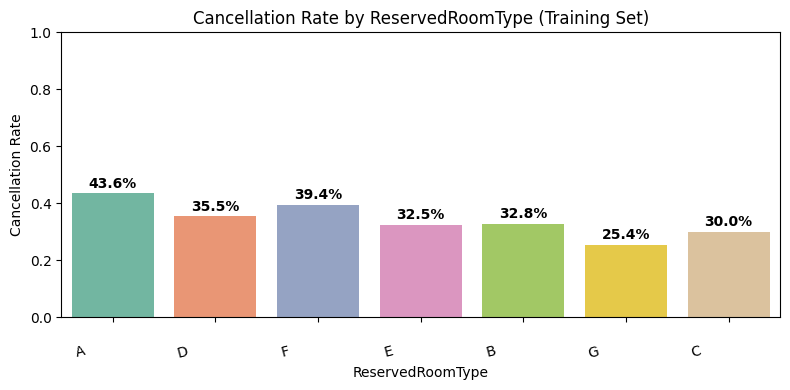

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'ReservedRoomType': X_train['ReservedRoomType'], 'IsCanceled': y_train}
    )
    .groupby('ReservedRoomType')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by ReservedRoomType (Training Set)')
plt.xlabel('ReservedRoomType')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
# Check summary and individual rows for room types 'P' and 'C' in the full dataset (df)
room_clean = df['ReservedRoomType'].str.strip()
pc_df = df[room_clean.isin(['P', 'C'])].copy()
pc_df['ReservedRoomType'] = pc_df['ReservedRoomType'].str.strip()

print("=== Summary in Full Dataset (df) ===")
print(
    pc_df.groupby('ReservedRoomType')['IsCanceled']
    .agg(total_bookings='count', canceled_count='sum', cancellation_rate='mean')
)

print("\n=== Breakdown in Train vs. Test ===")
for split_name, X_s, y_s in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    s_clean = X_s['ReservedRoomType'].str.strip()
    sub = pd.DataFrame({'ReservedRoomType': s_clean, 'IsCanceled': y_s})
    sub = sub[sub['ReservedRoomType'].isin(['P', 'C'])]
    print(f"\n{split_name}:")
    print(sub.groupby('ReservedRoomType')['IsCanceled'].agg(count='count', canceled='sum', rate='mean'))

print("\n=== Inspecting the 'P' rows directly ===")
display(pc_df[pc_df['ReservedRoomType'] == 'P'][['ReservedRoomType', 'AssignedRoomType', 'Adults', 'Children', 'Babies', 'ADR', 'MarketSegment', 'IsCanceled']])

=== Summary in Full Dataset (df) ===
                  total_bookings  canceled_count  cancellation_rate
ReservedRoomType                                                   
C                             14               5           0.357143
P                             10              10           1.000000

=== Breakdown in Train vs. Test ===

Train:
                  count  canceled  rate
ReservedRoomType                       
C                    10         3   0.3

Test:
                  count  canceled      rate
ReservedRoomType                           
C                     3         2  0.666667

=== Inspecting the 'P' rows directly ===


,ReservedRoomType,AssignedRoomType,Adults,Children,Babies,ADR,MarketSegment,IsCanceled
20591,P,P,0,0.0,0,0.0,Corporate,1
21184,P,P,0,0.0,0,0.0,Complementary,1
21185,P,P,0,0.0,0,0.0,Complementary,1
21189,P,P,0,0.0,0,0.0,Complementary,1
25847,P,P,0,0.0,0,0.0,Complementary,1
25848,P,P,0,0.0,0,0.0,Complementary,1
25849,P,P,0,0.0,0,0.0,Complementary,1
25850,P,P,0,0.0,0,0.0,Complementary,1
32907,P,P,0,0.0,0,0.0,Online TA,1
32908,P,P,0,0.0,0,0.0,Online TA,1


In [ ]:
removed = df.index.difference(X_train.index.union(X_test.index))
print(len(removed))
print(df.loc[removed, "ADR"].describe())
print(df.loc[removed, "ReservedRoomType"].value_counts())
print("Cancel rate in removed rows:", df.loc[removed, "IsCanceled"].mean().round(3))

169
count    169.000000
mean      11.148935
std       32.552647
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max      200.000000
Name: ADR, dtype: float64
ReservedRoomType
A                   111
D                    21
E                    16
P                    10
B                     5
F                     3
G                     2
C                     1
Name: count, dtype: int64
Cancel rate in removed rows: 0.148


In [ ]:
print(f"Total columns: {X_train.shape[1]}")
print("Column names:", X_train.columns.tolist())

# Also verify X_train and X_test have the exact same columns in the exact same order
assert list(X_train.columns) == list(X_test.columns), "Mismatch between X_train and X_test columns!"
print("Train and Test columns match identically.")

Total columns: 38
Column names: ['LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'Adults', 'Children', 'Babies', 'Country', 'IsRepeatedGuest', 'ReservedRoomType', 'AssignedRoomType', 'BookingChanges', 'DepositType', 'Agent', 'Company', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'TotalNights', 'WeekendOrNo', 'IsZeroNights', 'total_guests', 'Meal_BB       ', 'Meal_FB       ', 'Meal_HB       ', 'Meal_SC       ', 'MarketSegment_Aviation', 'MarketSegment_Complementary', 'MarketSegment_Corporate', 'MarketSegment_Direct', 'MarketSegment_Groups', 'MarketSegment_Offline TA/TO', 'MarketSegment_Online TA', 'has_prev_cancellation', 'has_prev_booking_ok']
Train and Test columns match identically.


In [ ]:
removed = df.index.difference(X_train.index.union(X_test.index))
r = df.loc[removed]

print("Removed rows:", len(r))
print("ADR == 0:            ", (r["ADR"] == 0).sum())
print("MarketSegment Undefined:", (r["MarketSegment"].str.strip() == "Undefined").sum())
print("DistributionChannel Undefined:", (r["DistributionChannel"].str.strip() == "Undefined").sum())
print("Zero guests:         ", ((r["Adults"] + r["Children"].fillna(0) + r["Babies"]) == 0).sum())
print("Zero nights:         ", ((r["StaysInWeekendNights"] + r["StaysInWeekNights"]) == 0).sum())
print("Children null:       ", r["Children"].isna().sum())
print("Country null:        ", r["Country"].isna().sum())
print("Complementary segment:", (r["MarketSegment"].str.strip() == "Complementary").sum())

print("\nMarketSegment:\n", r["MarketSegment"].value_counts())
print("\nDistributionChannel:\n", r["DistributionChannel"].value_counts())

Removed rows: 169
ADR == 0:             137
MarketSegment Undefined: 2
DistributionChannel Undefined: 2
Zero guests:          167
Zero nights:          67
Children null:        2
Country null:         8
Complementary segment: 15

MarketSegment:
 MarketSegment
Online TA        69
Offline TA/TO    35
Direct           21
Groups           16
Complementary    15
Corporate         9
Undefined         2
Aviation          2
Name: count, dtype: int64

DistributionChannel:
 DistributionChannel
TA/TO        114
Direct        31
Corporate     22
Undefined      2
Name: count, dtype: int64


assigned room type

In [ ]:
X_train = X_train.drop(columns="AssignedRoomType")
X_test = X_test.drop(columns="AssignedRoomType")

BookingChanges

In [ ]:
print(df["BookingChanges"].value_counts())

BookingChanges
0     69062
1      7232
2      2244
3       467
4       194
5        46
6        31
7        19
8         9
14        5
9         4
13        3
15        3
10        3
11        2
20        1
17        1
21        1
12        1
18        1
16        1
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
BookingChanges,,,
0,55201,25121,0.455082
1,5742,774,0.134796
2,1779,441,0.247892
3,356,71,0.199438
4,151,34,0.225166
5,37,10,0.270270
6,25,7,0.280000
7,12,0,0.000000
8,7,2,0.285714


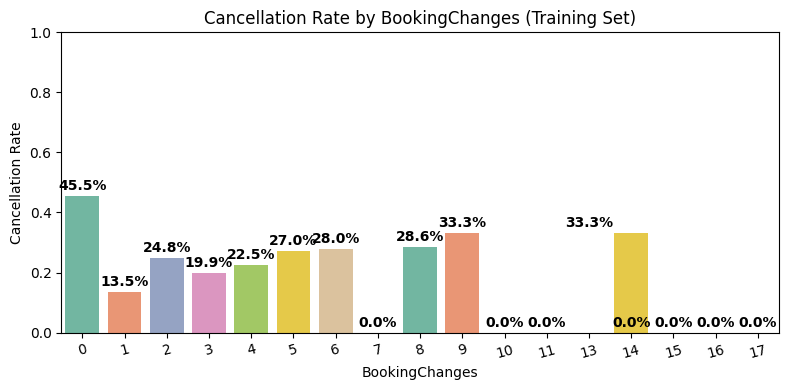

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'BookingChanges': X_train['BookingChanges'], 'IsCanceled': y_train}
    )
    .groupby('BookingChanges')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by BookingChanges (Training Set)')
plt.xlabel('BookingChanges')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

DepositType

In [ ]:
print(df["DepositType"].value_counts())

DepositType
No Deposit         66442
Non Refund         12868
Refundable            20
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
DepositType,,,
No Deposit,53061,16218,0.305648
Non Refund,10251,10232,0.998147
Refundable,16,12,0.750000


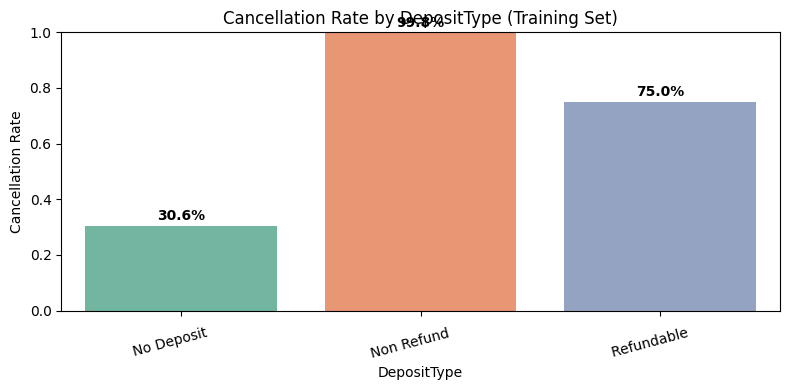

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'DepositType': X_train['DepositType'], 'IsCanceled': y_train}
    )
    .groupby('DepositType')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by DepositType (Training Set)')
plt.xlabel('DepositType')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

raw = df.loc[X_train.index].copy()          # raw, unencoded columns for the training rows
raw["y"] = y_train
raw["DepositType"] = raw["DepositType"].str.strip()
raw["MarketSegment"] = raw["MarketSegment"].str.strip()
raw["Country"] = raw["Country"].fillna("Missing")


# 1. Where does Non Refund sit? Share of each deposit type by market segment
print(pd.crosstab(raw["DepositType"], raw["MarketSegment"], normalize="index").round(3))



# 3. Does it hold within each market segment?
print(raw.groupby(["MarketSegment", "DepositType"])["y"].agg(["mean", "count"]).round(3))

# 4. Top countries among Non Refund bookings
print(raw[raw["DepositType"] == "Non Refund"]["Country"].value_counts().head(10))

MarketSegment  Aviation  Complementary  Corporate  Direct  Groups  \
DepositType                                                         
No Deposit        0.004          0.008      0.040   0.091   0.094   
Non Refund        0.000          0.000      0.024   0.001   0.598   
Refundable        0.000          0.000      0.188   0.062   0.000   

MarketSegment  Offline TA/TO  Online TA  
DepositType                              
No Deposit             0.179      0.583  
Non Refund             0.374      0.002  
Refundable             0.125      0.625  
                            mean  count
MarketSegment DepositType              
Aviation      No Deposit   0.237    186
Complementary No Deposit   0.107    441
Corporate     No Deposit   0.127   2137
              Non Refund   0.947    244
              Refundable   0.333      3
Direct        No Deposit   0.169   4825
              Non Refund   0.933     15
              Refundable   1.000      1
Groups        No Deposit   0.309   5000
    

In [ ]:
X_train.drop(columns=['DepositType', 'is_non_refund'], errors='ignore', inplace=True)
X_test.drop(columns=['DepositType', 'is_non_refund'], errors='ignore', inplace=True)

print("Remaining columns:", X_train.columns.tolist())


Remaining columns: ['LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'Adults', 'Children', 'Babies', 'Country', 'IsRepeatedGuest', 'ReservedRoomType', 'BookingChanges', 'Agent', 'Company', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'TotalNights', 'WeekendOrNo', 'IsZeroNights', 'total_guests', 'Meal_BB       ', 'Meal_FB       ', 'Meal_HB       ', 'Meal_SC       ', 'MarketSegment_Aviation', 'MarketSegment_Complementary', 'MarketSegment_Corporate', 'MarketSegment_Direct', 'MarketSegment_Groups', 'MarketSegment_Offline TA/TO', 'MarketSegment_Online TA', 'has_prev_cancellation', 'has_prev_booking_ok']


Agent

Agent is known at booking creation. It was target-encoded using scikit-learn’s TargetEncoder (smoothed, 5-fold cross-fitting) and fitted on the training split only. Missing agents were kept as their own level (No_Agent), and agents unseen in training fall back to the global cancellation rate.

,total_bookings,canceled_count,cancellation_rate
Agent,,,
9,25614,10693,0.417467
Other,15339,7136,0.465219
No_Agent,6428,2068,0.321717
1,5716,4213,0.737054
14,2913,506,0.173704
7,2814,371,0.131841
6,2155,775,0.359629
28,1323,91,0.068783
3,1026,609,0.593567


/tmp/ipykernel_977/3647583304.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


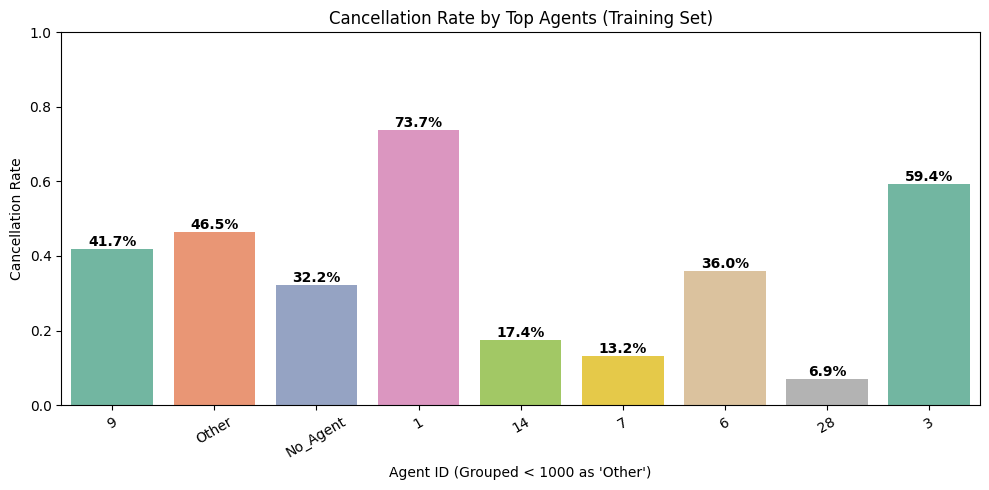

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Clean Agent values temporarily for inspection without modifying X_train
agent_clean = (
    X_train["Agent"]
    .fillna("No_Agent")
    .astype(str)
    .str.strip()
    .replace({"NULL": "No_Agent", "nan": "No_Agent"})
)

# Group rare agents (< 1000 bookings) into 'Other' so the table and chart stay readable
top_agents = agent_clean.value_counts()
major_agents = top_agents[top_agents >= 1000].index
agent_grouped = agent_clean.where(agent_clean.isin(major_agents), "Other")

# 1. Summary table sorted by total bookings
agent_summary = (
    pd.DataFrame({"Agent": agent_grouped, "IsCanceled": y_train})
    .groupby("Agent")["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
    .sort_values("total_bookings", ascending=False)
)

display(agent_summary)

# 2. Bar plot of cancellation rates across top agents
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=agent_summary.index,
    y=agent_summary["cancellation_rate"],
    palette="Set2",
)
plt.title("Cancellation Rate by Top Agents (Training Set)")
plt.ylabel("Cancellation Rate")
plt.xlabel("Agent ID (Grouped < 1000 as 'Other')")
plt.ylim(0, 1.0)
plt.xticks(rotation=30)

for p in ax.patches:
  ax.annotate(
      f"{p.get_height()*100:.1f}%",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="bottom",
      fontsize=10,
      fontweight="bold",
  )

plt.tight_layout()
plt.show()

In [ ]:
print("Missing in Train / Test:", X_train["Agent"].isna().sum(), X_test["Agent"].isna().sum())
print(X_train["Agent"].describe())

Missing in Train / Test: 0 0
count     63328
unique      213
top           9
freq      25614
Name: Agent, dtype: object


In [ ]:
for d in (X_train, X_test):
    d["Agent"] = (d["Agent"].astype(str).str.strip()
                  .replace({"NULL": "No_Agent", "nan": "No_Agent"}))

print("Unique agents in train:", X_train["Agent"].nunique())
print("Agents in test but not in train:", set(X_test["Agent"]) - set(X_train["Agent"]))

Unique agents in train: 213
Agents in test but not in train: {'197', '397', '331', '70', '408', '285', '453', '280', '144', '25', '90'}


In [ ]:
from sklearn.preprocessing import TargetEncoder

agent_te = TargetEncoder(target_type="binary", smooth="auto", cv=5, random_state=42)

# fit_transform on train: cross-fitted, so no row sees its own label
X_train["Agent_te"] = agent_te.fit_transform(X_train[["Agent"]], y_train).ravel()

# transform only on test: unseen agents fall back to the global mean
X_test["Agent_te"] = agent_te.transform(X_test[["Agent"]]).ravel()

X_train = X_train.drop(columns="Agent")
X_test = X_test.drop(columns="Agent")

print(X_train["Agent_te"].describe().round(3))

count    63328.000
mean         0.418
std          0.194
min          0.000
25%          0.322
50%          0.417
75%          0.419
max          1.000
Name: Agent_te, dtype: float64


In [ ]:
# Do the encoded values look sensible? Expect a spread from low (~0.07) to high (~0.74)
print(X_train["Agent_te"].round(2).value_counts().head(10))
print("Train mean:", X_train["Agent_te"].mean().round(3), "| y_train mean:", y_train.mean().round(3))

Agent_te
0.42    25732
0.32     7052
0.74     3409
0.13     2998
0.73     2717
0.17     2384
0.07     1479
0.36     1322
0.58     1036
0.59      762
Name: count, dtype: int64
Train mean: 0.418 | y_train mean: 0.418


Company

=== Binary Comparison: No Company vs. Has Company ===


,total_bookings,canceled_count,cancellation_rate
Booking_Type,,,
Has Company (Corporate),2921,615,0.210544
No Company (NULL),60407,25847,0.427881



=== Top Individual Companies (>= 100 bookings in Train) ===


,total_bookings,canceled_count,cancellation_rate
Company,,,
No_Company,60407,25847,0.427881
Other_Company,1393,333,0.239052
40,728,58,0.079670
67,213,140,0.657277
45,204,24,0.117647
153,168,41,0.244048
219,113,7,0.061947
174,102,12,0.117647


/tmp/ipykernel_977/3645883580.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(
/tmp/ipykernel_977/3645883580.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

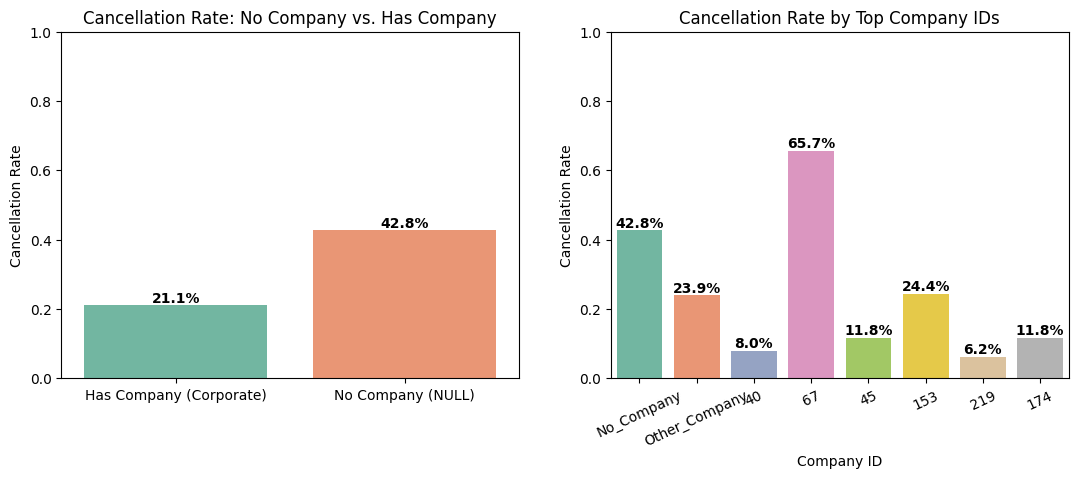

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Clean literal 'NULL' and missing values temporarily on X_train
company_clean = (
    X_train["Company"]
    .fillna("No_Company")
    .astype(str)
    .str.strip()
    .replace({"NULL": "No_Company", "nan": "No_Company"})
)

# 2. Check Binary Split: No Company ('NULL') vs. Has Company (Any Corporate ID)
has_company = (company_clean != "No_Company").map(
    {False: "No Company (NULL)", True: "Has Company (Corporate)"}
)
binary_summary = (
    pd.DataFrame({"Booking_Type": has_company, "IsCanceled": y_train})
    .groupby("Booking_Type")["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
)
print("=== Binary Comparison: No Company vs. Has Company ===")
display(binary_summary)

# 3. Check Top Individual Company IDs (to see if specific IDs differ or all behave similarly)
top_companies = company_clean.value_counts()
major_companies = top_companies[top_companies >= 100].index
company_grouped = company_clean.where(
    company_clean.isin(major_companies), "Other_Company"
)

detail_summary = (
    pd.DataFrame({"Company": company_grouped, "IsCanceled": y_train})
    .groupby("Company")["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
    .sort_values("total_bookings", ascending=False)
)
print("\n=== Top Individual Companies (>= 100 bookings in Train) ===")
display(detail_summary)

# 4. Side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot A: Binary (Has Company vs No Company)
ax1 = sns.barplot(
    x=binary_summary.index,
    y=binary_summary["cancellation_rate"],
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Cancellation Rate: No Company vs. Has Company")
axes[0].set_ylabel("Cancellation Rate")
axes[0].set_xlabel("")
axes[0].set_ylim(0, 1.0)
for p in ax1.patches:
  ax1.annotate(
      f"{p.get_height()*100:.1f}%",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="bottom",
      fontweight="bold",
  )

# Plot B: Top Companies
ax2 = sns.barplot(
    x=detail_summary.index,
    y=detail_summary["cancellation_rate"],
    palette="Set2",
    ax=axes[1],
)
axes[1].set_title("Cancellation Rate by Top Company IDs")
axes[1].set_ylabel("Cancellation Rate")
axes[1].set_xlabel("Company ID")
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis="x", rotation=25)
for p in ax2.patches:
  ax2.annotate(
      f"{p.get_height()*100:.1f}%",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="bottom",
      fontweight="bold",
  )

plt

In [ ]:
for d in (X_train, X_test):
    company_clean = (
        d["Company"]
        .fillna("No_Company")
        .astype(str)
        .str.strip()
        .replace({"NULL": "No_Company", "nan": "No_Company"})
    )
    d["has_company"] = (company_clean != "No_Company").astype(int)

X_train = X_train.drop(columns=["Company"])
X_test = X_test.drop(columns=["Company"])

print("Train has_company distribution:\n", X_train["has_company"].value_counts())

Train has_company distribution:
 has_company
0    60407
1     2921
Name: count, dtype: int64


In [ ]:
print(X_train.columns.tolist())

['LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'Adults', 'Children', 'Babies', 'Country', 'IsRepeatedGuest', 'ReservedRoomType', 'BookingChanges', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'TotalNights', 'WeekendOrNo', 'IsZeroNights', 'total_guests', 'Meal_BB       ', 'Meal_FB       ', 'Meal_HB       ', 'Meal_SC       ', 'MarketSegment_Aviation', 'MarketSegment_Complementary', 'MarketSegment_Corporate', 'MarketSegment_Direct', 'MarketSegment_Groups', 'MarketSegment_Offline TA/TO', 'MarketSegment_Online TA', 'has_prev_cancellation', 'has_prev_booking_ok', 'Agent_te', 'has_company']


DaysInWaitingList

=== DaysInWaitingList Summary (Train) ===
count    63328.000000
mean         3.204522
std         20.713924
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        391.000000
Name: DaysInWaitingList, dtype: float64

Exact 0 vs. > 0 counts:
DaysInWaitingList
0 days      60571
> 0 days     2757
Name: count, dtype: int64

Top 10 most frequent values:
DaysInWaitingList
0     60571
39      178
58      138
44      108
31      101
35       83
46       79
69       72
63       65
38       63
Name: count, dtype: int64

=== Cancellation Rate by Waiting List Group (Train) ===


,total_bookings,canceled_count,cancellation_rate
Wait_Group,,,
0 days,60571,24594,0.406036
1-30 days,446,354,0.793722
31-90 days,1661,1124,0.676701
> 90 days,650,390,0.600000


/tmp/ipykernel_977/1041262822.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


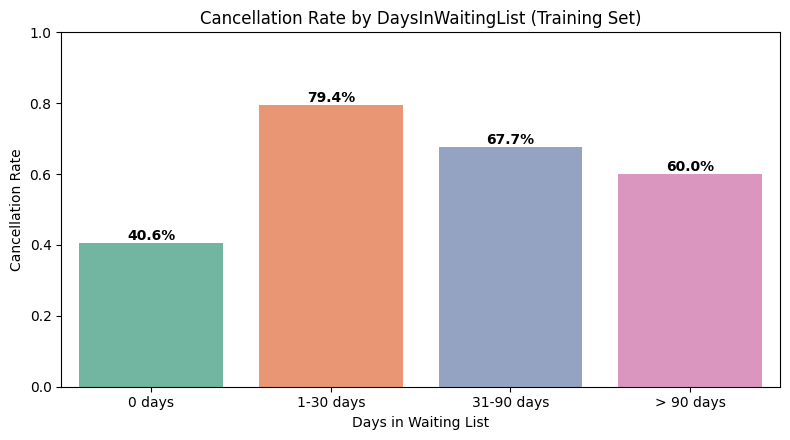

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Basic distribution & zero-inflation check
print("=== DaysInWaitingList Summary (Train) ===")
print(X_train["DaysInWaitingList"].describe())
print("\nExact 0 vs. > 0 counts:")
print((X_train["DaysInWaitingList"] > 0).value_counts().rename({False: "0 days", True: "> 0 days"}))

# 2. Top most frequent exact values
print("\nTop 10 most frequent values:")
print(X_train["DaysInWaitingList"].value_counts().head(10))

# 3. Cancellation rate comparison: 0 days vs. binned > 0 days
wait_bins = pd.cut(
    X_train["DaysInWaitingList"],
    bins=[-1, 0, 30, 90, X_train["DaysInWaitingList"].max()],
    labels=["0 days", "1-30 days", "31-90 days", "> 90 days"],
)

wait_summary = (
    pd.DataFrame({"Wait_Group": wait_bins, "IsCanceled": y_train})
    .groupby("Wait_Group", observed=False)["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
)

print("\n=== Cancellation Rate by Waiting List Group (Train) ===")
display(wait_summary)

# 4. Plot cancellation rate across waiting groups
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(
    x=wait_summary.index,
    y=wait_summary["cancellation_rate"],
    palette="Set2",
)
plt.title("Cancellation Rate by DaysInWaitingList (Training Set)")
plt.ylabel("Cancellation Rate")
plt.xlabel("Days in Waiting List")
plt.ylim(0, 1.0)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height()*100:.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

In [ ]:
X_train = X_train.drop(columns="DaysInWaitingList")
X_test = X_test.drop(columns="DaysInWaitingList")

CustomerType

In [ ]:
# Get the count and frequency of each unique value in the Meal column
cusType_counts = df["CustomerType"].value_counts()

print("Customer Type value counts:")
print(cusType_counts)

Customer Type value counts:
CustomerType
Transient          59404
Transient-Party    17333
Contract            2300
Group                293
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
CustomerType,,,
Transient,47459,21673,0.456668
Transient-Party,13821,3880,0.280732
Contract,1816,886,0.487885
Group,232,23,0.099138


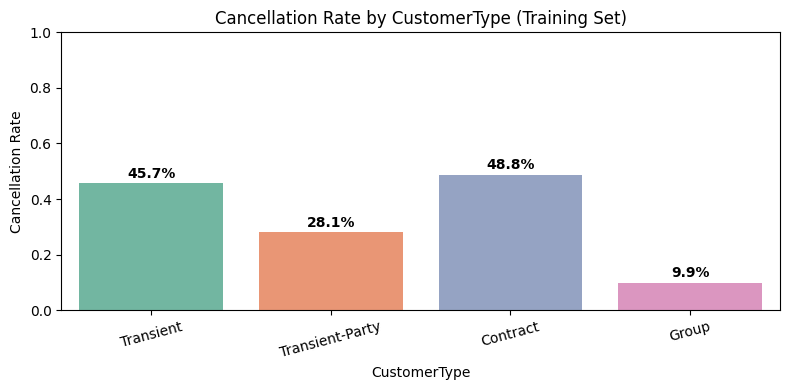

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'CustomerType': X_train['CustomerType'], 'IsCanceled': y_train}
    )
    .groupby('CustomerType')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by CustomerType (Training Set)')
plt.xlabel('CustomerType')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

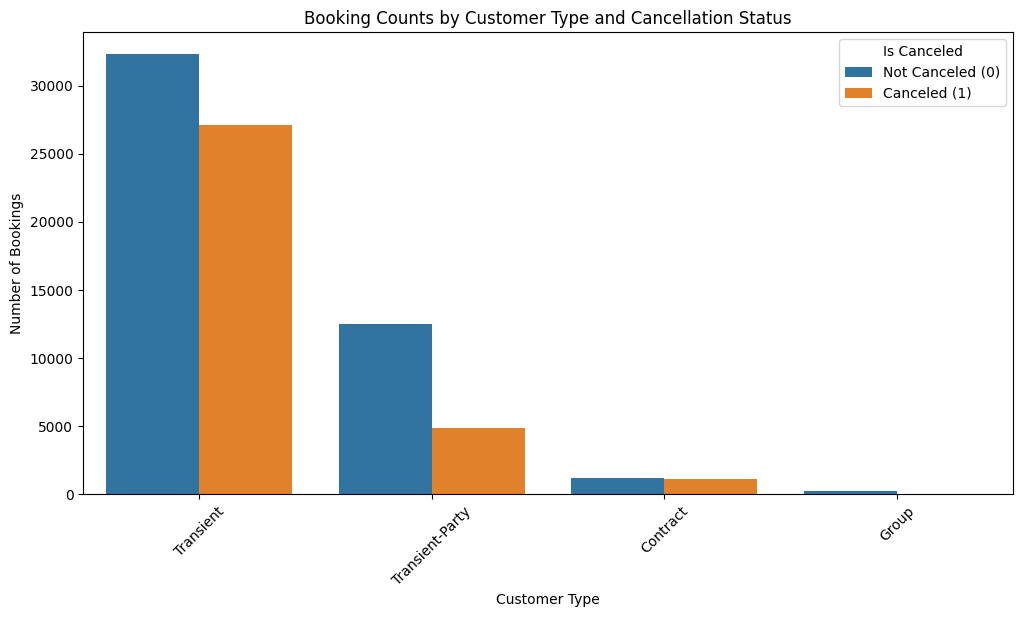

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(data=df, x='CustomerType', hue='IsCanceled')

plt.title('Booking Counts by Customer Type and Cancellation Status')
plt.xlabel('Customer Type')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.legend(title='Is Canceled', labels=['Not Canceled (0)', 'Canceled (1)'])
plt.show()

In [ ]:
for data in [X_train, X_test]:
    cust = data["CustomerType"].astype(str).str.strip()
    data["CustomerType_Transient_Party"] = (cust == "Transient-Party").astype(int)
    data["CustomerType_Contract"] = (cust == "Contract").astype(int)
    data["CustomerType_Group"] = (cust == "Group").astype(int)
    data.drop(columns=["CustomerType"], inplace=True)

ADR

=== ADR Summary (Train) ===
count    63328.000000
mean       105.549444
std         39.205900
min          0.000000
25%         79.200000
50%        100.000000
75%        126.000000
max        451.500000
Name: ADR, dtype: float64

Unique ADR values: 4820 out of 63328 rows
Zero ADR bookings (ADR == 0): 869
Negative ADR bookings (ADR < 0): 0

Top 10 most frequent ADR values:
ADR
62.0     2901
75.0     1865
90.0     1750
65.0     1655
95.0     1185
120.0    1175
80.0     1130
110.0    1118
100.0    1104
130.0     968
Name: count, dtype: int64

Top 5 highest ADR values (outlier check):
[451.5  375.5  372.33 365.   352.5 ]

=== Cancellation Rate by ADR Bracket (Train) ===


,total_bookings,canceled_count,cancellation_rate
ADR_Bracket,,,
<= 0 (Free/Promo),869,87,0.100115
0-75,12969,6355,0.490015
75-100,18832,7502,0.398364
100-125,14229,5797,0.407407
125-150,9004,3760,0.417592
150-200,6027,2439,0.404679
> 200,1398,522,0.373391


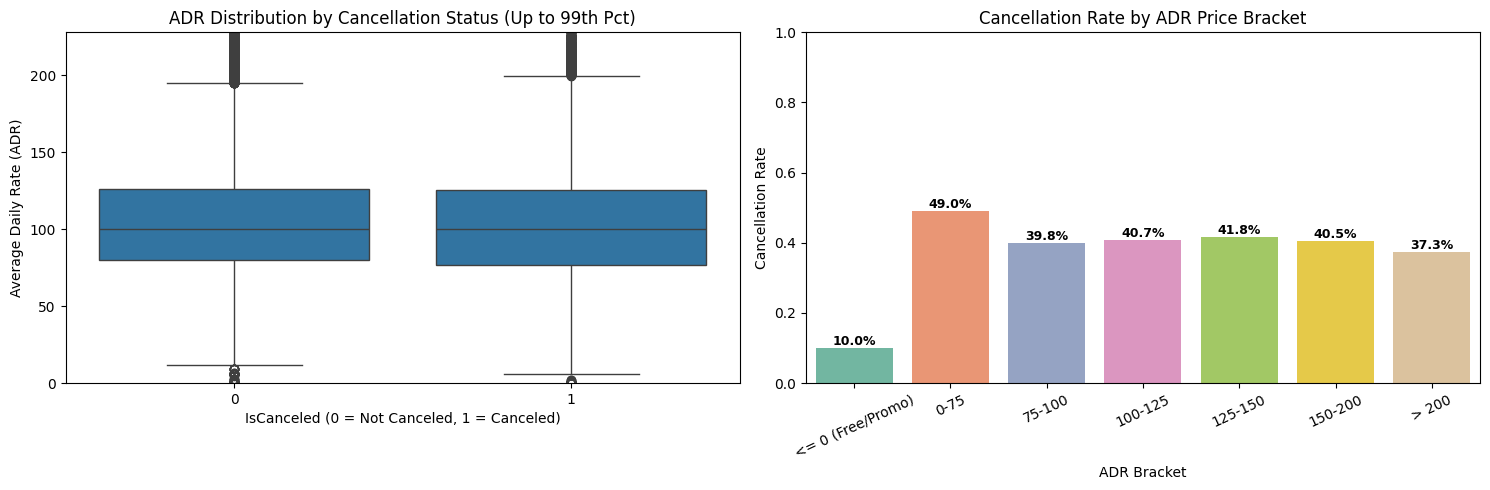

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Unique values & distribution summary (Training Set)
print("=== ADR Summary (Train) ===")
print(X_train["ADR"].describe())
print(f"\nUnique ADR values: {X_train['ADR'].nunique()} out of {len(X_train)} rows")
print(f"Zero ADR bookings (ADR == 0): {(X_train['ADR'] == 0).sum()}")
print(f"Negative ADR bookings (ADR < 0): {(X_train['ADR'] < 0).sum()}")
print("\nTop 10 most frequent ADR values:")
print(X_train["ADR"].value_counts().head(10))
print("\nTop 5 highest ADR values (outlier check):")
print(X_train["ADR"].nlargest(5).values)

# 2. Effect on IsCanceled across ADR price brackets
adr_bins = [-float("inf"), 0, 75, 100, 125, 150, 200, float("inf")]
adr_labels = ["<= 0 (Free/Promo)", "0-75", "75-100", "100-125", "125-150", "150-200", "> 200"]

adr_summary = (
    pd.DataFrame({
        "ADR_Bracket": pd.cut(X_train["ADR"], bins=adr_bins, labels=adr_labels),
        "IsCanceled": y_train,
    })
    .groupby("ADR_Bracket", observed=False)["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
)

print("\n=== Cancellation Rate by ADR Bracket (Train) ===")
display(adr_summary)

# 3. Side-by-side visualization: Distribution + Binned Cancellation Rate
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Boxplot capped at 99th percentile so extreme outliers don't squash the box
train_plot = pd.DataFrame({"ADR": X_train["ADR"], "IsCanceled": y_train})
sns.boxplot(data=train_plot, x="IsCanceled", y="ADR", ax=axes[0])
axes[0].set_ylim(0, X_train["ADR"].quantile(0.99))
axes[0].set_title("ADR Distribution by Cancellation Status (Up to 99th Pct)")
axes[0].set_xlabel("IsCanceled (0 = Not Canceled, 1 = Canceled)")
axes[0].set_ylabel("Average Daily Rate (ADR)")

# Right: Cancellation rate by ADR bracket
ax_bar = sns.barplot(
    x=adr_summary.index,
    y=adr_summary["cancellation_rate"],
    hue=adr_summary.index,
    palette="Set2",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Cancellation Rate by ADR Price Bracket")
axes[1].set_xlabel("ADR Bracket")
axes[1].set_ylabel("Cancellation Rate")
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis="x", rotation=25)

for p in ax_bar.patches:
    ax_bar.annotate(
        f"{p.get_height()*100:.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

In [ ]:
adr_cap = X_train["ADR"].quantile(0.999)  # 289.00

for data in [X_train, X_test]:
    data["is_free_stay"] = (data["ADR"] == 0).astype(int)
    data["ADR"] = data["ADR"].clip(lower=0, upper=adr_cap)

print("Train ADR min/max:", X_train["ADR"].min(), "/", X_train["ADR"].max())
print("Test ADR min/max:", X_test["ADR"].min(), "/", X_test["ADR"].max())

Train ADR min/max: 0.0 / 289.0
Test ADR min/max: 0.0 / 289.0


RequiredCarParkingSpaces

In [ ]:
carcounts = df["RequiredCarParkingSpaces"].value_counts()

print("car value counts:")
print(carcounts)

car value counts:
RequiredCarParkingSpaces
0    77404
1     1921
2        3
3        2
Name: count, dtype: int64


=== Booking Counts: Parking Required vs. IsCanceled (Train) ===


IsCanceled,0,1,All
RequiredCarParkingSpaces,,,
0 Spaces (No Parking),35328,26462,61790
> 0 Spaces (Needs Parking),1538,0,1538
All,36866,26462,63328



=== Row Percentages (% Canceled vs. Not Canceled) ===


IsCanceled,0,1
RequiredCarParkingSpaces,,
0 Spaces (No Parking),57.17,42.83
> 0 Spaces (Needs Parking),100.00,0.00



Chi-Square statistic: 1129.68 | p-value: 1.1714e-247
Pearson correlation with IsCanceled: -0.1337


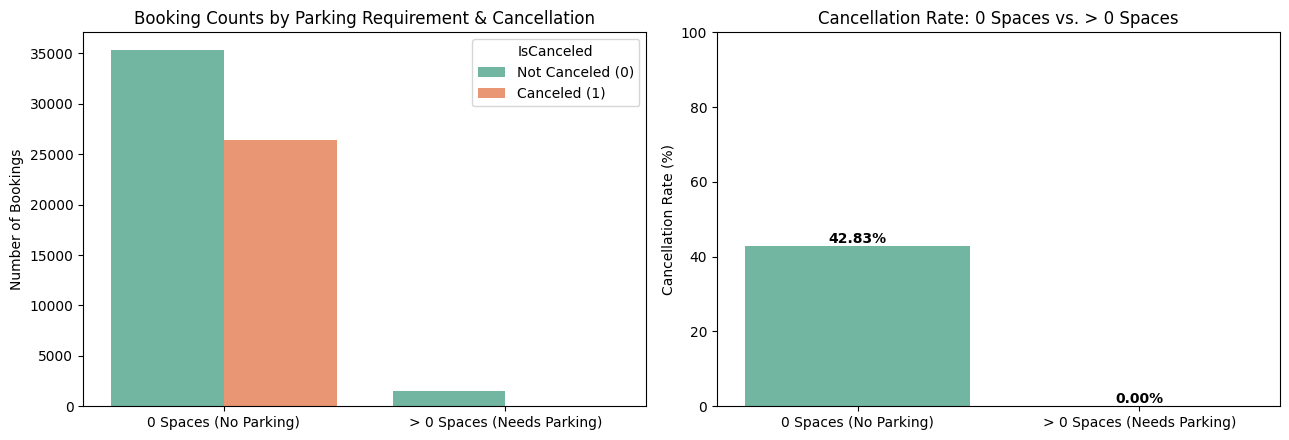

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

# 1. Exact crosstab: RequiredCarParkingSpaces (0 vs >0) vs IsCanceled (0 vs 1)
parking_binary = (X_train["RequiredCarParkingSpaces"] > 0).map(
    {False: "0 Spaces (No Parking)", True: "> 0 Spaces (Needs Parking)"}
)

ct_counts = pd.crosstab(parking_binary, y_train, margins=True)
ct_props = pd.crosstab(parking_binary, y_train, normalize="index") * 100

print("=== Booking Counts: Parking Required vs. IsCanceled (Train) ===")
display(ct_counts)

print("\n=== Row Percentages (% Canceled vs. Not Canceled) ===")
display(ct_props.round(2))

# 2. Chi-square test & correlation to verify statistical relationship
ct_raw = pd.crosstab(X_train["RequiredCarParkingSpaces"] > 0, y_train)
chi2, p_val, _, _ = chi2_contingency(ct_raw)
corr = (X_train["RequiredCarParkingSpaces"] > 0).astype(int).corr(y_train)

print(f"\nChi-Square statistic: {chi2:.2f} | p-value: {p_val:.4e}")
print(f"Pearson correlation with IsCanceled: {corr:.4f}")

# 3. Visual comparison: Counts + Cancellation Rate
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(
    x=parking_binary,
    hue=y_train,
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Booking Counts by Parking Requirement & Cancellation")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of Bookings")
axes[0].legend(title="IsCanceled", labels=["Not Canceled (0)", "Canceled (1)"])

rate_df = ct_props.reset_index()
ax_bar = sns.barplot(
    data=rate_df,
    x=parking_binary.name if parking_binary.name else "RequiredCarParkingSpaces",
    y=1,
    hue=parking_binary.name if parking_binary.name else "RequiredCarParkingSpaces",
    palette="Set2",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Cancellation Rate: 0 Spaces vs. > 0 Spaces")
axes[1].set_xlabel("")
axes[1].set_ylabel("Cancellation Rate (%)")
axes[1].set_ylim(0, 100)

for p in ax_bar.patches:
    ax_bar.annotate(
        f"{p.get_height():.2f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

In [ ]:
for data in [X_train, X_test]:
    data["needs_parking"] = (data["RequiredCarParkingSpaces"] > 0).astype(int)
    data.drop(columns=["RequiredCarParkingSpaces"], inplace=True)

print("Train needs_parking value counts:\n", X_train["needs_parking"].value_counts())
print("\nTest needs_parking value counts:\n", X_test["needs_parking"].value_counts())

Train needs_parking value counts:
 needs_parking
0    61790
1     1538
Name: count, dtype: int64

Test needs_parking value counts:
 needs_parking
0    15451
1      382
Name: count, dtype: int64


TotalOfSpecialRequests

=== TotalOfSpecialRequests Value Counts (Train) ===
TotalOfSpecialRequests
0    38289
1    17048
2     6547
3     1273
4      149
5       22
Name: count, dtype: int64

=== Cancellation Rate by TotalOfSpecialRequests (Train) ===


,total_bookings,canceled_count,cancellation_rate
TotalOfSpecialRequests,,,
0,38289,21060,0.550027
1,17048,3734,0.219029
2,6547,1415,0.216130
3,1273,234,0.183818
4,149,19,0.127517
5,22,0,0.000000


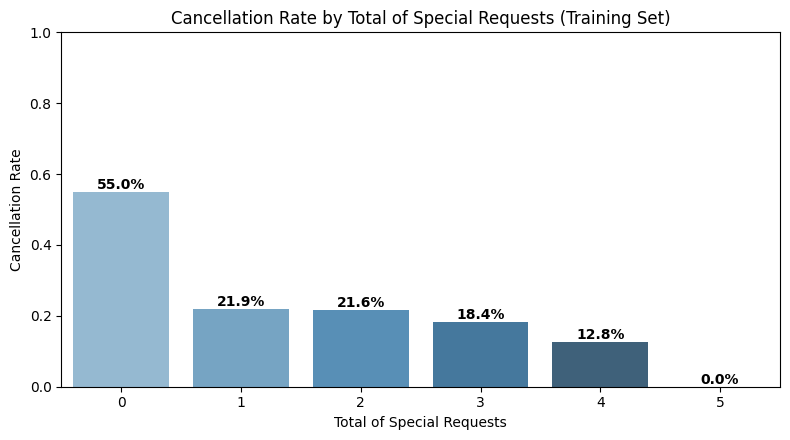

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

print("=== TotalOfSpecialRequests Value Counts (Train) ===")
print(X_train["TotalOfSpecialRequests"].value_counts().sort_index())

request_summary = (
    pd.DataFrame({
        "TotalOfSpecialRequests": X_train["TotalOfSpecialRequests"],
        "IsCanceled": y_train,
    })
    .groupby("TotalOfSpecialRequests")["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
)

print("\n=== Cancellation Rate by TotalOfSpecialRequests (Train) ===")
display(request_summary)

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(
    x=request_summary.index.astype(str),
    y=request_summary["cancellation_rate"],
    hue=request_summary.index.astype(str),
    palette="Blues_d",
    legend=False,
)
plt.title("Cancellation Rate by Total of Special Requests (Training Set)")
plt.xlabel("Total of Special Requests")
plt.ylabel("Cancellation Rate")
plt.ylim(0, 1.0)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height()*100:.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()